# Wine Prediction Model Report

---
embed-resources: true
echo: false
---

## Introduction

The purpose of this report is to present the development of a model to replicate a Sommelier, designed to evaluate and predict the quality of wines given its physicochemical properties. 

The goal of this model is to provide the startup with an automated, data-driven alternative to human Sommeliers with potential implications like reducing the need for human expertise, while maintaining consistent evaluations.

## Methods

Below are the various imports that were used towards building this model. 

<u>**These are general imports for visualizations, muting warnings, and accessing the pandas library, as well as exporting the model:**</u>
```
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from joblib import dump
import warnings
warnings.filterwarnings('ignore')
```

<u>**These imports are related to model building and scoring:**</u>
```
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_score
```

<u>**These imports were used for model preprocessing:**</u>
```
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
```

In [19]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from joblib import dump
import warnings
warnings.filterwarnings('ignore')

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_score

from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

### Data

To achieve the goal for building this model, we used wine quality data provided in the following parquet files: 

* train data: wine-train.parquet

* test data: wine-test.parquet 

This data was originally sources in the following paper: 

* Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009). Modeling wine preferences by data mining from physicochemical properties. Decision support systems, 47(4), 547-553. https://doi.org/10.1016/j.dss.2009.05.016

but became a standard dataset made avaliable via the UC Irvine Machine Learning Repository. Though the original data contained two datasets, split by red wine and white wine, we've combined the data and added a column for the color of wine. 

<u>**Data dictionary for reference**</u>

**`quality`**

- `[int64]` the quality of the wine based on evaluation by a minimum of three sensory assessors (using blind tastes), which graded the wine in a scale that ranges from 0 (very bad) to 10 (excellent)

**`color`**

- `[object]` the (human perceivable) color of the wine, red or white

**`fixed acidity`**

- `[float64]` grams of tartaric acid per cubic decimeter

**`volatile acidity`**

- `[float64]` grams of acetic acid per cubic decimeter

**`citric acid`**

- `[float64]` grams of citric acid per cubic decimeter

**`residual sugar`**

- `[float64]` grams of residual sugar per cubic decimeter

**`chlorides`**

- `[float64]` grams of sodium chloride cubic decimeter

**`free sulfur dioxide`**

- `[float64]` milligrams of free sulfur dioxide per cubic decimeter

**`total sulfur dioxide`**

- `[float64]` milligrams of total sulfur dioxide per cubic decimeter

**`density`**

- `[float64]` the total density of the wine in grams per cubic centimeter

**`pH`**

- `[float64]` the acidity of the wine measured using [pH](https://en.m.wikipedia.org/wiki/PH)

**`sulphates`**

- `[float64]` grams of potassium sulphate cubic decimeter

**`alcohol`**

- `[float64]` percent [alcohol by volume](https://en.m.wikipedia.org/wiki/Alcohol_by_volume)

<u>**First few rows of training data**</u>

In [2]:
wine_train = pd.read_parquet("https://lab.cs307.org/wine/data/wine-train.parquet")
wine_test = pd.read_parquet("https://lab.cs307.org/wine/data/wine-test.parquet")

In [3]:
wine_train.head(5)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color
0,7.6,0.23,0.64,12.9,0.033,54.0,170.0,0.99800,3.00,0.53,8.8,5,white
1,NaN,0.75,0.01,2.2,0.059,11.0,18.0,0.99242,3.39,0.40,NaN,6,red
2,7.4,0.67,0.12,1.6,0.186,5.0,21.0,0.99600,3.39,0.54,9.5,5,red
3,6.4,0.18,0.74,NaN,0.046,54.0,168.0,0.99780,3.58,0.68,10.1,5,white
4,6.7,0.35,0.32,9.0,0.032,29.0,113.0,0.99188,3.13,0.65,12.9,7,white


<u>**First few rows of testing data**</u>

In [4]:
wine_test.head(5)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color
0,6.0,0.260,0.50,2.20,0.048,59.0,153.0,0.99280,3.08,0.61,9.8,5,white
1,7.3,0.300,0.74,13.50,0.039,46.0,165.0,0.99820,3.02,0.40,8.7,5,white
2,9.1,0.360,0.39,1.80,0.060,21.0,55.0,0.99495,3.18,0.82,11.0,7,red
3,6.6,0.260,0.36,1.20,0.035,43.0,126.0,0.99094,3.01,0.63,11.4,6,white
4,5.2,0.285,0.29,5.15,0.035,64.0,138.0,0.98950,3.19,0.34,12.4,8,white


<u>**General summary statistics of data**</u>

In [5]:
summary_wine = wine_train.describe().transpose().drop(columns = 'count').rename(columns = {'25%' : '25th percentile', '50%' : '50th percentile', '75%' : '75th percentile'})
summary_wine

,mean,std,min,25th percentile,50th percentile,75th percentile,max
fixed acidity,7.220579,1.295282,3.80000,6.40000,7.0000,7.70000,15.90000
volatile acidity,0.342403,0.166465,0.08000,0.23000,0.3000,0.41000,1.33000
citric acid,0.316478,0.145276,0.00000,0.24000,0.3100,0.39000,1.23000
residual sugar,5.430406,4.750618,0.60000,1.80000,3.0000,8.10000,65.80000
chlorides,0.056358,0.035460,0.01200,0.03800,0.0480,0.06600,0.61100
free sulfur dioxide,30.600048,17.906396,1.00000,17.00000,29.0000,41.00000,289.00000
total sulfur dioxide,115.221915,56.581139,6.00000,77.00000,118.0000,155.00000,440.00000
density,0.994710,0.003004,0.98711,0.99238,0.9949,0.99699,1.03898
pH,3.218454,0.159184,2.74000,3.11000,3.2100,3.32000,4.01000
sulphates,0.531784,0.150914,0.23000,0.43000,0.5050,0.60000,2.00000


In [6]:
print('Number of missing entries per feature: ')
wine_train.isnull().sum()

Number of missing entries per feature: 


fixed acidity           170
volatile acidity          0
citric acid             199
residual sugar          240
chlorides                 0
free sulfur dioxide      24
total sulfur dioxide      0
density                   0
pH                      236
sulphates               223
alcohol                 196
quality                   0
color                     0
dtype: int64

<u>**Various Visualizations of the Data**</u>

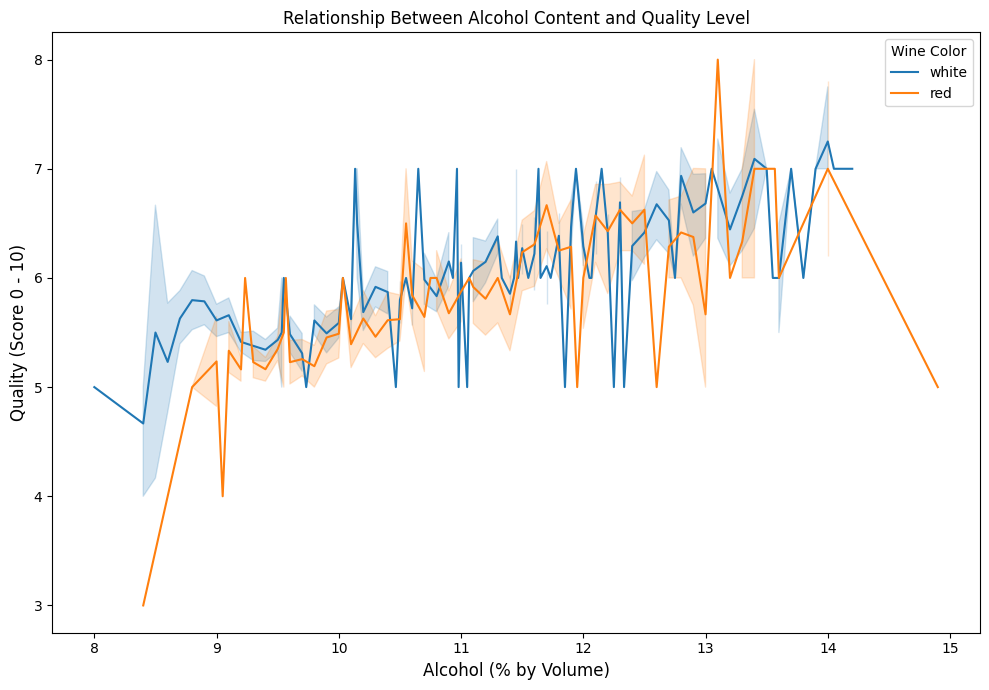

In [7]:
plt.figure(figsize = (10,7))
sns.lineplot(data = wine_train, x = 'alcohol', y = 'quality', hue = 'color')
plt.xlabel("Alcohol (% by Volume)", fontsize = 12)
plt.ylabel("Quality (Score 0 - 10)", fontsize = 12)
plt.title("Relationship Between Alcohol Content and Quality Level", fontsize = 12)
plt.legend(title = "Wine Color")
plt.tight_layout()
plt.show()

::: {.quarto-figure-caption}
Figure 1. Line plot of alcohol content versus wine quality score, showing that higher-alcohol wines tend to score slightly better. This suggests alcohol concentration could be an informative predictor for modeling quality.

:::

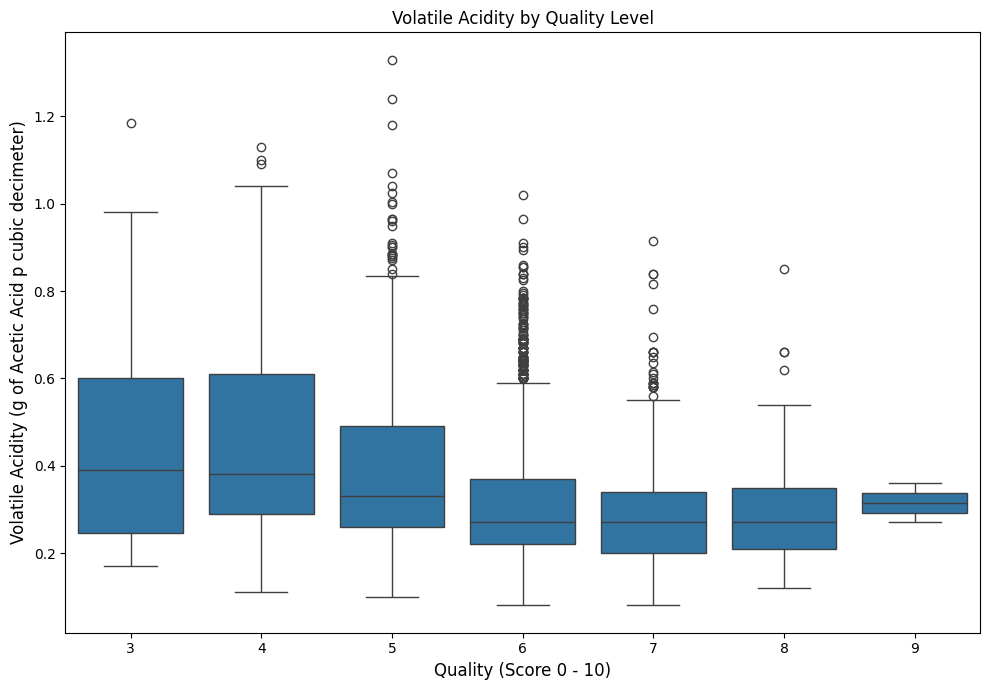

In [8]:
plt.figure(figsize = (10,7))
sns.boxplot(data = wine_train, x = "quality", y = "volatile acidity")
plt.xlabel("Quality (Score 0 - 10)", fontsize = 12)
plt.ylabel("Volatile Acidity (g of Acetic Acid p cubic decimeter)", fontsize = 12)
plt.title("Volatile Acidity by Quality Level", fontsize = 12)
plt.tight_layout()
plt.show()

:::{.quarto-figure-caption}
Figure 2. Boxplots show that lower quality wines tend to have higher volatile acidity, indicating that excess acetic acid reduces perceived quality.
:::

### Models

To prepare for model development, the data was split into 'X' and 'y' train and test sets. Target variable was the quality of the wine (y), and the feature variables (X) both numeric and categoric, were used. For model preprocessing, two pipelines were created from the `StandardScaler` and `OneHotEncoder` imports, with the former being used to impute missing values be standardized with the mean and the latter being used to impute missing values with the most frequent category and one-hot encoded. These two pipelines would be combined using the `ColumnTransformer`. The numeric and categorical faetures used were all the ones in the training dataset, using `select_dtypes` to get them, though manual entry would've sufficed as well. This preprocessor was then fit and transformed to the training data.

```
X_train = wine_train.drop("quality", axis=1)
y_train = wine_train["quality"]

X_test = wine_test.drop("quality", axis=1)
y_test = wine_test["quality"]

numeric_transformer = make_pipeline(SimpleImputer(strategy = 'mean'), StandardScaler())
categorical_transformer = make_pipeline(SimpleImputer(strategy = "most_frequent"), OneHotEncoder())

numeric_features = X_train.select_dtypes(include = ['int64', 'float64']).columns
categorical_features = X_train.select_dtypes(include = ['object', 'category']).columns

preprocessor = make_column_transformer((numeric_transformer, numeric_features), (categorical_transformer, categorical_features))
preprocessor.fit(X_train)
preprocessor.transform(X_train)
```

In [9]:
X_train = wine_train.drop("quality", axis=1)
y_train = wine_train["quality"]

X_test = wine_test.drop("quality", axis=1)
y_test = wine_test["quality"]

numeric_transformer = make_pipeline(SimpleImputer(strategy = 'mean'), StandardScaler())
categorical_transformer = make_pipeline(SimpleImputer(strategy = "most_frequent"), OneHotEncoder())

numeric_features = X_train.select_dtypes(include = ['int64', 'float64']).columns
categorical_features = X_train.select_dtypes(include = ['object', 'category']).columns

preprocessor = make_column_transformer((numeric_transformer, numeric_features), (categorical_transformer, categorical_features))
preprocessor.fit(X_train)
preprocessor.transform(X_train);

To make the model, a K-Nearest Neighbors Classifier was defined as an estimator since it provides a simple yet effective baseline for both numerical and categorical features. `make_pipeline` was used to apply the preprocessing steps to the model, which was then fit to the training data and evaluated on the test set. This estimator was then used to return a model using `GridSearchCV` to perform an exhaustive search over hyperparameters, optimizing the number of neighbors, distance metric, and weighting scheme through cross-validation. The resulting best combination of parameters was then used to generate predictions and evaluate model performance on unseen data.

```
knn = make_pipeline(preprocessor, KNeighborsClassifier()) 

param_grid = {
    'kneighborsclassifier__n_neighbors' : [10, 50, 100, 300], 
    'kneighborsclassifier__p' : [1, 2],
    'kneighborsclassifier__weights': ['uniform', 'distance'],
    'kneighborsclassifier__n_jobs' : [1, 5, 10, 25]
}
model = GridSearchCV(
    estimator = knn,
    param_grid = param_grid
)
model.fit(X_train, y_train)
```

In [10]:
# train models
knn = make_pipeline(preprocessor, KNeighborsClassifier())
# knn.get_params().keys() <- help get parameter keys 

param_grid = {
    'kneighborsclassifier__n_neighbors' : [10, 50, 100, 300], 
    'kneighborsclassifier__p' : [1, 2],
    'kneighborsclassifier__weights': ['uniform', 'distance'],
    'kneighborsclassifier__n_jobs' : [1, 5, 10, 25]
}
model = GridSearchCV(
    estimator = knn,
    param_grid = param_grid
)
model.fit(X_train, y_train)

,estimator,Pipeline(step...lassifier())])
,param_grid,"{'kneighborsclassifier__n_jobs': [1, 5, ...], 'kneighborsclassifier__n_neighbors': [10, 50, ...], 'kneighborsclassifier__p': [1, 2], 'kneighborsclassifier__weights': ['uniform', 'distance']}"
,scoring,None
,n_jobs,None
,refit,True
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('pipeline-1', ...), ('pipeline-2', ...)]"


## Results

To evaluate model performance, we calculated the model’s accuracy and cross-validation scores, where accuracy measures the proportion of correctly classified samples, and cross-validation scores gauges  the model’s consistency and generalizability across different subsets of the training data.

```
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print('Accuracy score for model: ' + str(accuracy))

scores = cross_val_score(model.best_estimator_, X_train, y_train, cv = 5)
print("Mean CV accuracy:", scores.mean())
```

In [20]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print('Accuracy score for model: ' + str(accuracy))

scores = cross_val_score(model.best_estimator_, X_train, y_train, cv = 5)
print("Mean CV accuracy:", scores.mean())

Accuracy score for model: 0.6413461538461539
Mean CV accuracy: 0.6191977922799222


**The model achevived an accuracy score of ~0.6413 and a cross validation score of ~0.6192**

We can also visualize our model performance using a confusion matrix

<Figure size 1100x800 with 0 Axes>

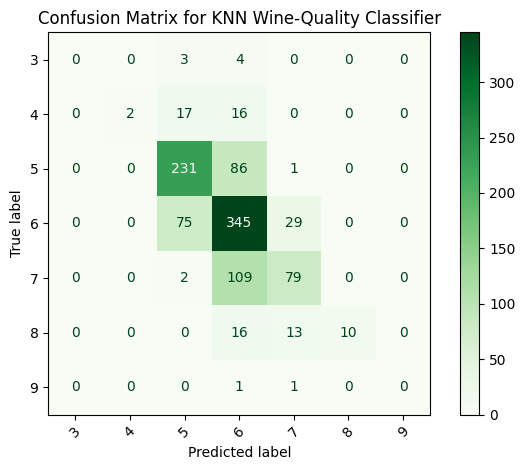

In [18]:
plt.figure(figsize = (11, 8))
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap = "Greens", xticks_rotation = 45)
plt.title("Confusion Matrix for KNN Wine-Quality Classifier", fontsize = 12)
plt.tight_layout()
plt.show()

::: {.quarto-figure-caption}
Figure 3. Confusion matrix of actual vs. predicted wine quality, showing that the KNN classifier most accurately predicts mid-range qualities (5–6) and confuses adjacent categories most often.

:::

## Discussion

### Would I deploy this model?
I would <b> NOT </b> deploy this model. The current model at this point in time shouldn't be deployed without better measures put into place in all the processes taken to build it like preprocessing and hyperparameter tuning. It's current performance measured by the accuracy and cross validation score further support this sentiment. 

### Risks avoided by not using this model:
- Classification errors/confusion in the model (eg., problems highlighted in Figure 3)
- The scale of real-world data is much greater than the small subset of data used in this model
    - Unclear as to weather or not KNClassifier model could scale to that level
- This model cannot accurately predict something that's typically associated with human subjectivity 

### Potential improvements
- Try other classifiers to create our model 
    - This could help us not only improve performance of the model on not just this data, but also  data of greater magnitudes 
- Fine-tune more hyperparameters on our model to further optimize potential model performance
- Add/create new features to be used for predicting the target

## Conclusion

Though our model doesn't serve as a great way of predicting wine quality, it represents a good starting point as a solid concept/potential framework for future wine quality classification models. Its subpar accuracy and cross validation scores make it hard to recommend this for practical use. The design and preprocessing could be further improved for model stability and model scaling. If these potential improvements are made, our approach could potentially be employed.